# Problema 2 - Fruits and Vegetables Recognizer (CNN)
## Text Mining & Image Recognition - Proyecto Final

Instrucciones construir un clasificador de imagenes basado en una CNN capaz de distinguir **3 frutas y 3 vegetales**, probando al menos 3 arquitecturas y seleccionando la mejor segun metricas de validacion y prueba.



## 1. **importar librerias**


In [4]:
import os
import shutil
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models, optimizers
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow', tf.__version__)

TensorFlow 2.20.0


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Carga y seleccion de clases

seleccion de frutas y vegetales y se fusiona fresh + roten en una clase por categoria para distinguir tipos de f y v

6 Clases a dejar: Apple, Banana, Orange (frutas) | Bellpepper, Carrot, Tomato (vegetales).

In [6]:
from google.colab import drive
drive.mount('/content/drive')

from PIL import Image

# Ruta de frutas y verduras en Drive
DRIVE_PATH = '/content/drive/MyDrive/TextMining/Dataset_problema2/Fruits_Vegetables_Dataset(12000)'

# Mapeo: clase final -> [carpetas Fresh, Rotten] que se fusionan
CLASS_MAP = {
    'Apple':      ['Fruits/FreshApple',      'Fruits/RottenApple'],
    'Banana':     ['Fruits/FreshBanana',     'Fruits/RottenBanana'],
    'Orange':     ['Fruits/FreshOrange',     'Fruits/RottenOrange'],
    'Bellpepper': ['Vegetables/FreshBellpepper', 'Vegetables/RottenBellpepper'],
    'Carrot':     ['Vegetables/FreshCarrot',     'Vegetables/RottenCarrot'],
    'Tomato':     ['Vegetables/FreshTomato',     'Vegetables/RottenTomato'],
}

DATA_DIR = '/content/data'          # directorio reorganizado (6 subcarpetas)
TEST_DIR = '/content/data_test'     # 10% para test (separado manualmente)
READY_MARKER = os.path.join(DATA_DIR, '.ready')

# Idempotente: si ya se copio y valido antes, saltar (evita re-copiar 7k imagenes)
if os.path.exists(READY_MARKER):
    print('DATA_DIR ya copiado y validado. Se omite la copia.')
    print('Para forzar re-copia, elimina /content/data y vuelve a ejecutar esta celda.')
else:
    if os.path.exists(DATA_DIR):
        shutil.rmtree(DATA_DIR)
    if os.path.exists(TEST_DIR):
        shutil.rmtree(TEST_DIR)

    for cls in CLASS_MAP:
        os.makedirs(os.path.join(DATA_DIR, cls), exist_ok=True)

    total_copiadas = 0
    for cls, subdirs in CLASS_MAP.items():
        all_files = []
        for sd in subdirs:
            src = os.path.join(DRIVE_PATH, sd)
            if not os.path.isdir(src):
                print('AVISO: no existe', src)
                continue
            for f in os.listdir(src):
                if f.lower().endswith(('.jpg', '.jpeg', '.png')):
                    all_files.append(os.path.join(src, f))
        for i, fp in enumerate(all_files):
            dst = os.path.join(DATA_DIR, cls, f'{cls}_{i}{os.path.splitext(fp)[1].lower()}')
            shutil.copy(fp, dst)
        total_copiadas += len(all_files)
        print(f'  Copiadas {len(all_files):4d} imagenes para {cls}')
    print(f'Total copiado: {total_copiadas} imagenes.')

    # Validacion: eliminar archivos corruptos/truncados que PIL no pueda cargar.
    # (Evita el error UnidentifiedImageError durante el entrenamiento.)
    corruptos = 0
    for cls in CLASS_MAP:
        d = os.path.join(DATA_DIR, cls)
        for fn in os.listdir(d):
            fp = os.path.join(d, fn)
            try:
                with Image.open(fp) as im:
                    im.load()
            except Exception:
                os.remove(fp)
                corruptos += 1
    print(f'Archivos corruptos/truncados eliminados: {corruptos}')

    # Marcar como listo solo si la copia y validacion completaron
    open(READY_MARKER, 'w').close()

print('Clases y numero de imagenes (fusionadas Fresh+Rotten):')
for cls in CLASS_MAP:
    n = len(os.listdir(os.path.join(DATA_DIR, cls)))
    print(f'  {cls:<12}{n}')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  Copiadas 1195 imagenes para Apple
  Copiadas 1196 imagenes para Banana
  Copiadas 1200 imagenes para Orange
  Copiadas 1202 imagenes para Bellpepper
  Copiadas 1198 imagenes para Carrot
  Copiadas 1199 imagenes para Tomato
Total copiado: 7190 imagenes.
Archivos corruptos/truncados eliminados: 0
Clases y numero de imagenes (fusionadas Fresh+Rotten):
  Apple       1195
  Banana      1196
  Orange      1200
  Bellpepper  1202
  Carrot      1198
  Tomato      1199


## 3. exploracion de imagnes

imagenes ejemplo para ver contenido

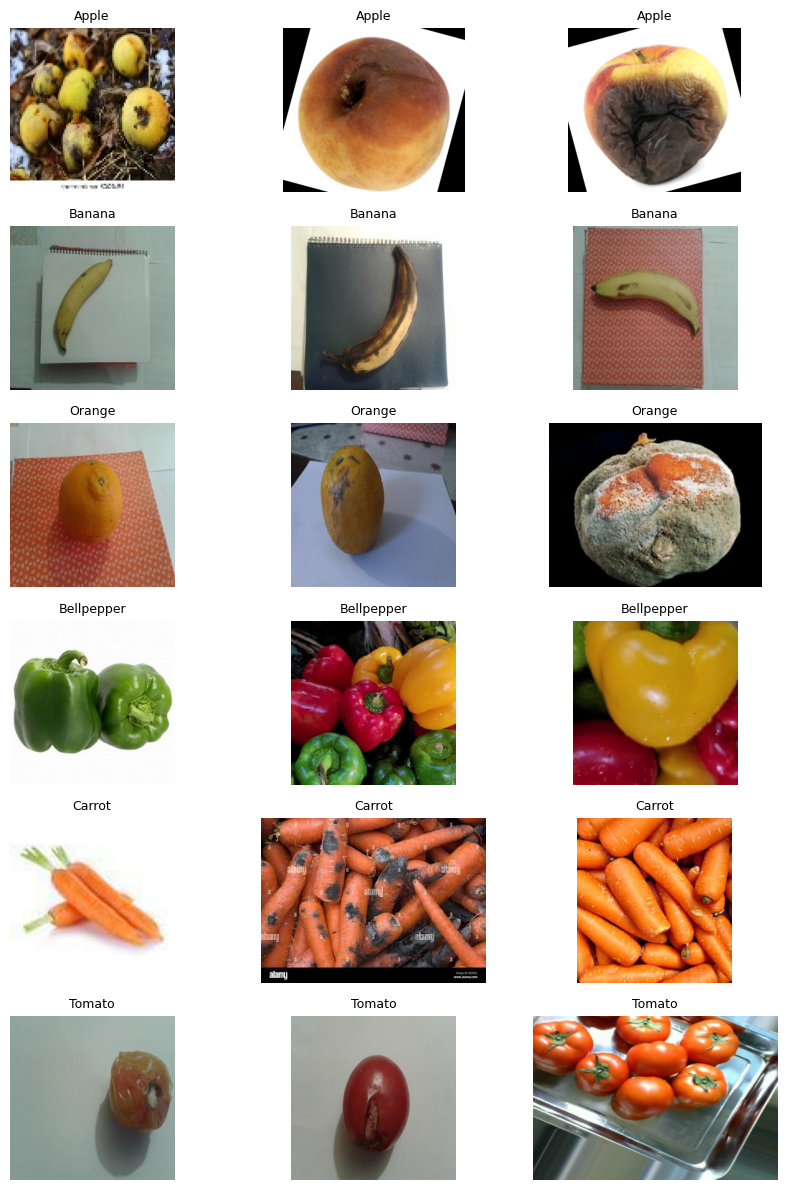

In [7]:
import matplotlib.image as mpimg

fig, axes = plt.subplots(6, 3, figsize=(9, 12))
for r, cls in enumerate(CLASS_MAP):
    files = os.listdir(os.path.join(DATA_DIR, cls))
    samples = random.sample(files, min(3, len(files)))
    for c, fn in enumerate(samples):
        img = mpimg.imread(os.path.join(DATA_DIR, cls, fn))
        axes[r, c].imshow(img)
        axes[r, c].set_title(cls, fontsize=9)
        axes[r, c].axis('off')
plt.tight_layout()
plt.show()

## 4. Organizacion de directorios (train / val / test)
10% para data_test y resto para data con imagedatagenerator 70 train - 20 validation y 10 test

In [8]:
TEST_FRACTION = 0.10
SPLIT_MARKER = os.path.join(TEST_DIR, '.split_done')

# Idempotente: si el split ya se hizo, no repetir (evita mover otro 10%)
if os.path.exists(SPLIT_MARKER):
    print('Split train/test ya realizado. Se omite.')
else:
    os.makedirs(TEST_DIR, exist_ok=True)
    for cls in CLASS_MAP:
        os.makedirs(os.path.join(TEST_DIR, cls), exist_ok=True)
        src_dir = os.path.join(DATA_DIR, cls)
        files = os.listdir(src_dir)
        random.shuffle(files)
        n_test = int(len(files) * TEST_FRACTION)
        for fn in files[:n_test]:
            shutil.move(os.path.join(src_dir, fn), os.path.join(TEST_DIR, cls, fn))
    open(SPLIT_MARKER, 'w').close()

print('Tras separar test:')
for cls in CLASS_MAP:
    n_train = len(os.listdir(os.path.join(DATA_DIR, cls)))
    n_test  = len(os.listdir(os.path.join(TEST_DIR, cls)))
    print(f'  {cls:<12}train/val={n_train:<6} test={n_test}')


Tras separar test:
  Apple       train/val=1076   test=119
  Banana      train/val=1077   test=119
  Orange      train/val=1080   test=120
  Bellpepper  train/val=1082   test=120
  Carrot      train/val=1079   test=119
  Tomato      train/val=1080   test=119


## 5. preprocesamiento: color, tama;o y normalizacion

- Color RGB (a color): el color es un discriminante clave entre clases (naranja vs manzana roja, zanahoria vs tomate). Trabajar en grises perderia esta señal.
- Tamanio: 128×128 px — para tener balance entre forma y color y cantidad de computo usada.
- Normalizacion 0–1: con rescale=1./255 dentro del imagedatagen.


In [9]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
NUM_CLASSES = len(CLASS_MAP)
print(f'Tamaño imagen: {IMG_SIZE} | Clases: {NUM_CLASSES} | Color: RGB')

Tamaño imagen: (128, 128) | Clases: 6 | Color: RGB


## 6. Data Aumentation
se usa:
- rotation_range: rotacion.
- zoom_range + width/height_shift: escalado.
- horizontal_flip: flip.
- brightness_range: iluminacion.
- shear_range: deformacion extra.

In [10]:
# Generador de entrenamiento CON augmentacion
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.7, 1.3],
    validation_split=0.2
)

# Generador de validacion SIN augmentacion (solo rescale + split)
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

# Generador de test SIN augmentacion (directorio aparte)
test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    seed=SEED
)

val_gen = val_datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    seed=SEED
)

test_gen = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print('indices de clase:', train_gen.class_indices)

Found 5181 images belonging to 6 classes.
Found 1293 images belonging to 6 classes.
Found 716 images belonging to 6 classes.
indices de clase: {'Apple': 0, 'Banana': 1, 'Bellpepper': 2, 'Carrot': 3, 'Orange': 4, 'Tomato': 5}


## 7. CNN 1 —baseline

CNN basica con 2 bloques conv+pool, flatten y 1 capa densa.


In [11]:
def build_cnn1():
    model = models.Sequential([
        layers.Conv2D(32, (3,3), activation='relu', input_shape=(*IMG_SIZE, 3)),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

cnn1 = build_cnn1()
cnn1.summary()

EPOCHS = 15
history1 = cnn1.fit(train_gen, epochs=EPOCHS, validation_data=val_gen)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,393,094 (28.20 MB)

 Trainable params: 7,393,094 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
101/162 ━━━━━━━━━━━━━━━━━━━━ 17s 287ms/step - accuracy: 0.2683 - loss: 2.1806

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


162/162 ━━━━━━━━━━━━━━━━━━━━ 55s 313ms/step - accuracy: 0.4379 - loss: 1.5341 - val_accuracy: 0.4826 - val_loss: 1.4241
Epoch 2/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 46s 283ms/step - accuracy: 0.6593 - loss: 0.9587 - val_accuracy: 0.6636 - val_loss: 1.1272
Epoch 3/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 46s 287ms/step - accuracy: 0.7182 - loss: 0.8021 - val_accuracy: 0.6481 - val_loss: 1.1828
Epoch 4/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 48s 296ms/step - accuracy: 0.7610 - loss: 0.6981 - val_accuracy: 0.6597 - val_loss: 1.1077
Epoch 5/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 46s 286ms/step - accuracy: 0.7827 - loss: 0.6315 - val_accuracy: 0.6442 - val_loss: 1.0805
Epoch 6/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 46s 286ms/step - accuracy: 0.8004 - loss: 0.5742 - val_accuracy: 0.7100 - val_loss: 0.9993
Epoch 7/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 51s 314ms/step - accuracy: 0.8228 - loss: 0.5267 - val_accuracy: 0.6976 - val_loss: 1.0139
Epoch 8/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 48s 297ms/step - accuracy: 0.8207 - loss: 0.5139 - val

## 8. Resultados CNN 1

grafica de accuracy y loss de val y train para detectar sobreajuste y comparar.

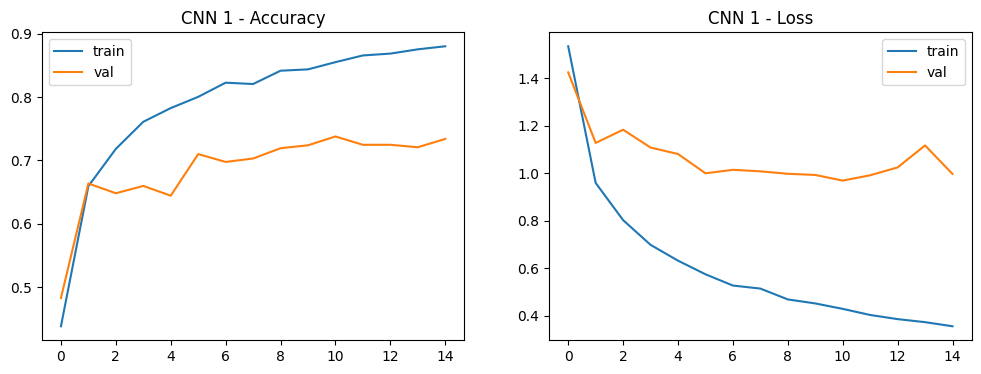

23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 130ms/step - accuracy: 0.8883 - loss: 0.4120
CNN 1 - Test accuracy: 0.8883 | Test loss: 0.4120


In [12]:
def plot_history(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist.history['accuracy'], label='train')
    ax[0].plot(hist.history['val_accuracy'], label='val')
    ax[0].set_title(f'{title} - Accuracy')
    ax[0].legend()
    ax[1].plot(hist.history['loss'], label='train')
    ax[1].plot(hist.history['val_loss'], label='val')
    ax[1].set_title(f'{title} - Loss')
    ax[1].legend()
    plt.show()

plot_history(history1, 'CNN 1')

test_loss1, test_acc1 = cnn1.evaluate(test_gen)
print(f'CNN 1 - Test accuracy: {test_acc1:.4f} | Test loss: {test_loss1:.4f}')

## 9. CNN 2 — filtros y capa conv adicional

se aniade un tercer bloque a la cnn1 conv con 128 filtros y mas neuronas densas.

Capas conv: 3 / Filtrosde 32, 64, 128 * Kernel de 3×3 / Pooling: Max 2×2
Activacion: ReLU / Neuronas densas: 256
Optimizador: epocas: 15

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,517,574 (24.86 MB)

 Trainable params: 6,517,574 (24.86 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 54s 315ms/step - accuracy: 0.4669 - loss: 1.3848 - val_accuracy: 0.5638 - val_loss: 1.3448
Epoch 2/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 48s 297ms/step - accuracy: 0.6522 - loss: 0.9590 - val_accuracy: 0.5886 - val_loss: 1.2052
Epoch 3/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 48s 295ms/step - accuracy: 0.7197 - loss: 0.7743 - val_accuracy: 0.6272 - val_loss: 1.2258
Epoch 4/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 49s 305ms/step - accuracy: 0.7732 - loss: 0.6531 - val_accuracy: 0.6636 - val_loss: 1.0875
Epoch 5/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 47s 293ms/step - accuracy: 0.8180 - loss: 0.5366 - val_accuracy: 0.6527 - val_loss: 1.0879
Epoch 6/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 48s 294ms/step - accuracy: 0.8429 - loss: 0.4640 - val_accuracy: 0.7108 - val_loss: 0.9360
Epoch 7/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 49s 303ms/step - accuracy: 0.8483 - loss: 0.4405 - val_accuracy: 0.7370 - val_loss: 0.9479
Epoch 8/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 48s 297ms/step - accuracy: 0.8693 - loss: 0

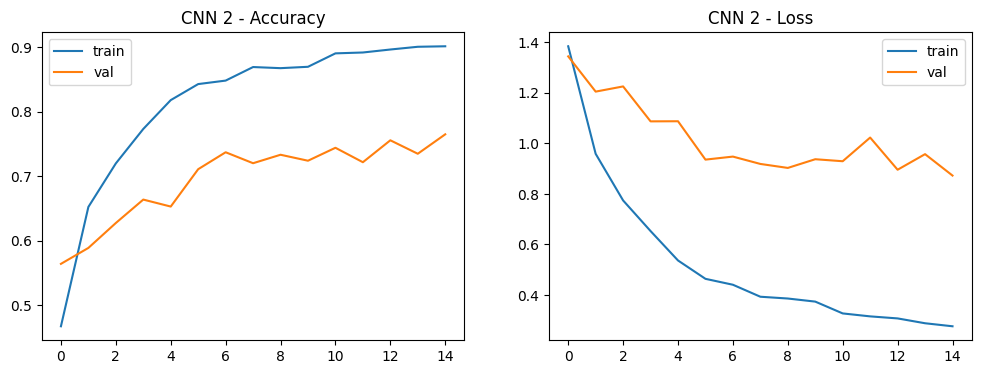

23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - accuracy: 0.9022 - loss: 0.3380
CNN 2 - Test accuracy: 0.9022 | Test loss: 0.3380


In [13]:
def build_cnn2():
    model = models.Sequential([
        layers.Conv2D(32, (3,3), activation='relu', input_shape=(*IMG_SIZE, 3)),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(128, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

cnn2 = build_cnn2()
cnn2.summary()

history2 = cnn2.fit(train_gen, epochs=EPOCHS, validation_data=val_gen)
plot_history(history2, 'CNN 2')

test_loss2, test_acc2 = cnn2.evaluate(test_gen)
print(f'CNN 2 - Test accuracy: {test_acc2:.4f} | Test loss: {test_loss2:.4f}')

## 10. CNN 3 — Con dropout - regularizacion

se anñaden dropout sobre la cnn 3 para reducir sobreajuste
con  3 capas convolucionales, fitros 32,64 y 128, kernel de 3x3 y pooling max d 2x2
relu, 256 neuronas densas, droout 0.5, 15 epoch

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,517,574 (24.86 MB)

 Trainable params: 6,517,574 (24.86 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 56s 322ms/step - accuracy: 0.4059 - loss: 1.4802 - val_accuracy: 0.4957 - val_loss: 1.4147
Epoch 2/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 48s 296ms/step - accuracy: 0.5891 - loss: 1.1136 - val_accuracy: 0.5855 - val_loss: 1.2217
Epoch 3/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 49s 304ms/step - accuracy: 0.6659 - loss: 0.9304 - val_accuracy: 0.5545 - val_loss: 1.2584
Epoch 4/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 48s 295ms/step - accuracy: 0.7132 - loss: 0.7881 - val_accuracy: 0.6512 - val_loss: 1.0489
Epoch 5/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 48s 295ms/step - accuracy: 0.7672 - loss: 0.6629 - val_accuracy: 0.6589 - val_loss: 1.0537
Epoch 6/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 50s 306ms/step - accuracy: 0.7883 - loss: 0.6091 - val_accuracy: 0.6852 - val_loss: 0.9626
Epoch 7/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 48s 297ms/step - accuracy: 0.8220 - loss: 0.5394 - val_accuracy: 0.7022 - val_loss: 0.9359
Epoch 8/15
162/162 ━━━━━━━━━━━━━━━━━━━━ 51s 314ms/step - accuracy: 0.8292 - loss: 0

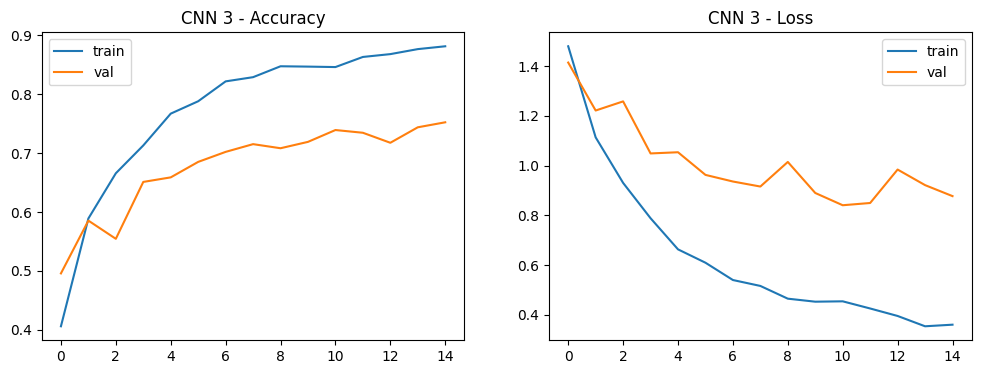

23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 127ms/step - accuracy: 0.8911 - loss: 0.3231
CNN 3 - Test accuracy: 0.8911 | Test loss: 0.3231


In [14]:
def build_cnn3():
    model = models.Sequential([
        layers.Conv2D(32, (3,3), activation='relu', input_shape=(*IMG_SIZE, 3)),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(128, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

cnn3 = build_cnn3()
cnn3.summary()

history3 = cnn3.fit(train_gen, epochs=EPOCHS, validation_data=val_gen)
plot_history(history3, 'CNN 3')

test_loss3, test_acc3 = cnn3.evaluate(test_gen)
print(f'CNN 3 - Test accuracy: {test_acc3:.4f} | Test loss: {test_loss3:.4f}')

## 11. Comparacion de las 3 arquitecturas

accuracy  y loss de train/val/test de las 3 CNN.


In [15]:
def best(hist, key):
    return max(hist.history[key])

results = pd.DataFrame({
    'Arquitectura': ['CNN 1 (2 conv)', 'CNN 2 (3 conv)', 'CNN 3 (3 conv + Dropout)'],
    'Acc train':    [best(history1,'accuracy'), best(history2,'accuracy'), best(history3,'accuracy')],
    'Acc val':      [best(history1,'val_accuracy'), best(history2,'val_accuracy'), best(history3,'val_accuracy')],
    'Acc test':     [test_acc1, test_acc2, test_acc3],
    'Loss test':    [test_loss1, test_loss2, test_loss3],
})
results['Gap train-val'] = results['Acc train'] - results['Acc val']
print(results.to_string(index=False))

            Arquitectura  Acc train  Acc val  Acc test  Loss test  Gap train-val
          CNN 1 (2 conv)   0.880332 0.737819  0.888268   0.411993       0.142513
          CNN 2 (3 conv)   0.901563 0.764888  0.902235   0.338037       0.136676
CNN 3 (3 conv + Dropout)   0.881683 0.752514  0.891061   0.323127       0.129170


## 12. Seleccion de la mejor arquitectura

**Que se hace:** elegimos la arquitectura con **mejor balance** entre accuracy de validacion/prueba y la menor brecha train-val (menos sobreajuste). **No se selecciona por train accuracy aislado.**

**Resultado:** modelo final eleguido.
**Como ayuda:** cumple el criterio del PDF.

In [16]:
# Seleccion automatica: para mjor acuracy de test con menor gap train-val
results['score'] = results['Acc test'] - results['Gap train-val']
best_idx = results['score'].idxmax()
best_model_name = results.loc[best_idx, 'Arquitectura']
print(f'Modelo seleccionado: {best_model_name}')

# asigna el modelo
models_dict = {'CNN 1 (2 conv)': cnn1, 'CNN 2 (3 conv)': cnn2, 'CNN 3 (3 conv + Dropout)': cnn3}
final_model = models_dict[best_model_name]
final_history = {0: history1, 1: history2, 2: history3}[best_idx]

Modelo seleccionado: CNN 2 (3 conv)


## 13. Evaluacion con el conjunto de prueba

evaluar modelo sobre testgen y genera la matriz de confusion.

23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 102ms/step
              precision    recall  f1-score   support

       Apple       0.78      0.91      0.84       119
      Banana       0.94      0.92      0.93       119
  Bellpepper       0.85      0.95      0.90       120
      Carrot       0.96      0.94      0.95       119
      Orange       0.96      0.88      0.92       120
      Tomato       0.97      0.82      0.89       119

    accuracy                           0.90       716
   macro avg       0.91      0.90      0.90       716
weighted avg       0.91      0.90      0.90       716



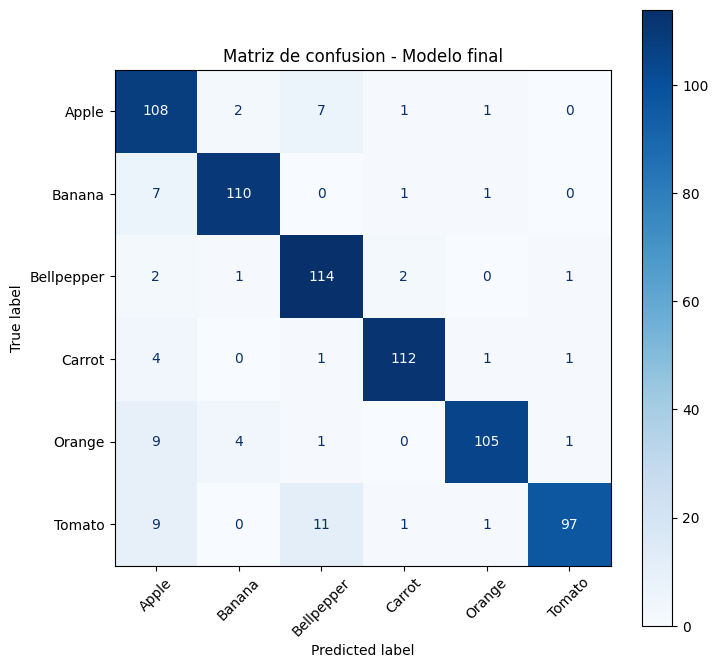

In [17]:
# Predicciones s/ test
test_gen.reset()
y_pred = final_model.predict(test_gen, verbose=1)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_gen.classes
class_names = list(test_gen.class_indices.keys())

# Reporte
print(classification_report(y_true, y_pred_classes, target_names=class_names))

# Matriz de confusion
cm = confusion_matrix(y_true, y_pred_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45)
plt.title('Matriz de confusion - Modelo final')
plt.show()

## 14. ¿Por que cree que la CNN que selecciono funciona mejor que otras?

La CNN 2 seleccionada obtuvo un accuracy de prueba de **0.902** y una brecha train-val de **0.137**, frente a CNN 1 (Acc test 0.888, gap 0.143) y CNN 3 (Acc test 0.891, gap 0.129). La diferencia se explica por:

- Mayor capacidad: CNN 2 incluye 3 capas convolucionales, lo que le permite extraer patrones mas complejos que CNN 1 (solo 2 conv). Esto mejoró la precision sin caer en sobreajuste.
- regularizaacion -Dropout: CNN 3 incorporó Dropout y redujo ligeramente la brecha train-val, pero sacrificó algo de rendimiento en test. CNN 2 logró un balance más favorable entre capacidad y generalizacin.
- Generalizacion: la brecha train-val de CNN 2 fue menor que la de CNN 1, indicando mejor capacidad de generalizar a datos nuevos, y su accuracy de prueba fue el más alto de las tres.

La selección NO se basa solo en accuracy de entrenamiento, sino en la combinación de validación, prueba y la diferencia entrenamiento-validación. CNN 2 mostró el mejor equilibrio entre rendimiento y estabilidad.


## 15. Conclusiones

- clases: 3 frutas (apple, banana, orange) + 3 vegetales (bellpepper, carrot, tomato), fusionando fresh+rotten (6 clases).  
- preprocesamiento: color rgb (color discriminante), tamaño 128×128, normalización 0–1.  
- data augmentation: rotación, escalado/zoom, flip horizontal, iluminación (brightness_range), shear  por medio de imagedatagenerator + flow_from_directory.  
- split: 70% train / 20% val / 10% test.  
- arquitecturas probadas: 3 cnn (baseline, +capa/filtros, +dropout).  
- modelo seleccionado:cnn 2 (3 conv), porque alcanzó el mejor equilibrio entre capacidad y generalización: accuracy de prueba más alto (0.902) y brecha train-val moderada (0.137).  
- resultado de test final: 90% accuracy, con métricas macro y weighted avg de 0.91 en precisión, recall y f1-score. la matriz de confusión muestra que todas las clases fueron clasificadas con alta exactitud, destacando carrot y banana (>0.93 f1-score).
